# PR 4 – CNN from Scratch: CIFAR-10 Image Classifier

## Task A1: Data Loading, EDA & Preprocessing

### A1.1 – Load CIFAR-10 Dataset

**Objective:**
Load the CIFAR-10 dataset using TensorFlow/Keras
and inspect its dimensions, labels and data types.

**Expected Output:**
- Training images: (50000, 32, 32, 3)
- Testing images: (10000, 32, 32, 3)
- Labels: 0 to 9
- Image data type: uint8

Import libraries and load the dataset

In [7]:
import os
import tarfile
import pickle
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

# Dataset file location
dataset_path = Path("data/cifar-10-python.tar.gz")

# Check whether the file exists
if not dataset_path.exists():
    raise FileNotFoundError("CIFAR-10 file not found. Check your data folder.")

# Extract dataset
with tarfile.open(dataset_path, "r:gz") as tar:
    tar.extractall(path="data")

print("Dataset extracted successfully!")

# Function to load CIFAR-10 batches
def load_batch(file_path):
    with open(file_path, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = batch[b"data"]
    labels = batch[b"labels"]

    images = images.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)

# Load training batches
X_train_list = []
y_train_list = []

for i in range(1, 6):
    images, labels = load_batch(
        f"data/cifar-10-batches-py/data_batch_{i}"
    )
    X_train_list.append(images)
    y_train_list.append(labels)

X_train = np.concatenate(X_train_list)
y_train = np.concatenate(y_train_list)

# Load test batch
X_test, y_test = load_batch(
    "data/cifar-10-batches-py/test_batch"
)

# Display dataset information
print("\nTraining Images Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Testing Images Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nTraining Data Type:", X_train.dtype)
print("Testing Data Type:", X_test.dtype)

print("\nUnique Labels:", np.unique(y_train))
print("Number of Classes:", len(np.unique(y_train)))

Dataset extracted successfully!

Training Images Shape: (50000, 32, 32, 3)
Training Labels Shape: (50000,)
Testing Images Shape: (10000, 32, 32, 3)
Testing Labels Shape: (10000,)

Training Data Type: uint8
Testing Data Type: uint8

Unique Labels: [0 1 2 3 4 5 6 7 8 9]
Number of Classes: 10


### A1.2 – Visualise Sample Images

**Objective:**
Visualise five sample images from each of the ten CIFAR-10 classes.

**Expected Output:**
A 5 × 10 image grid containing 50 images, with class names displayed above each column.

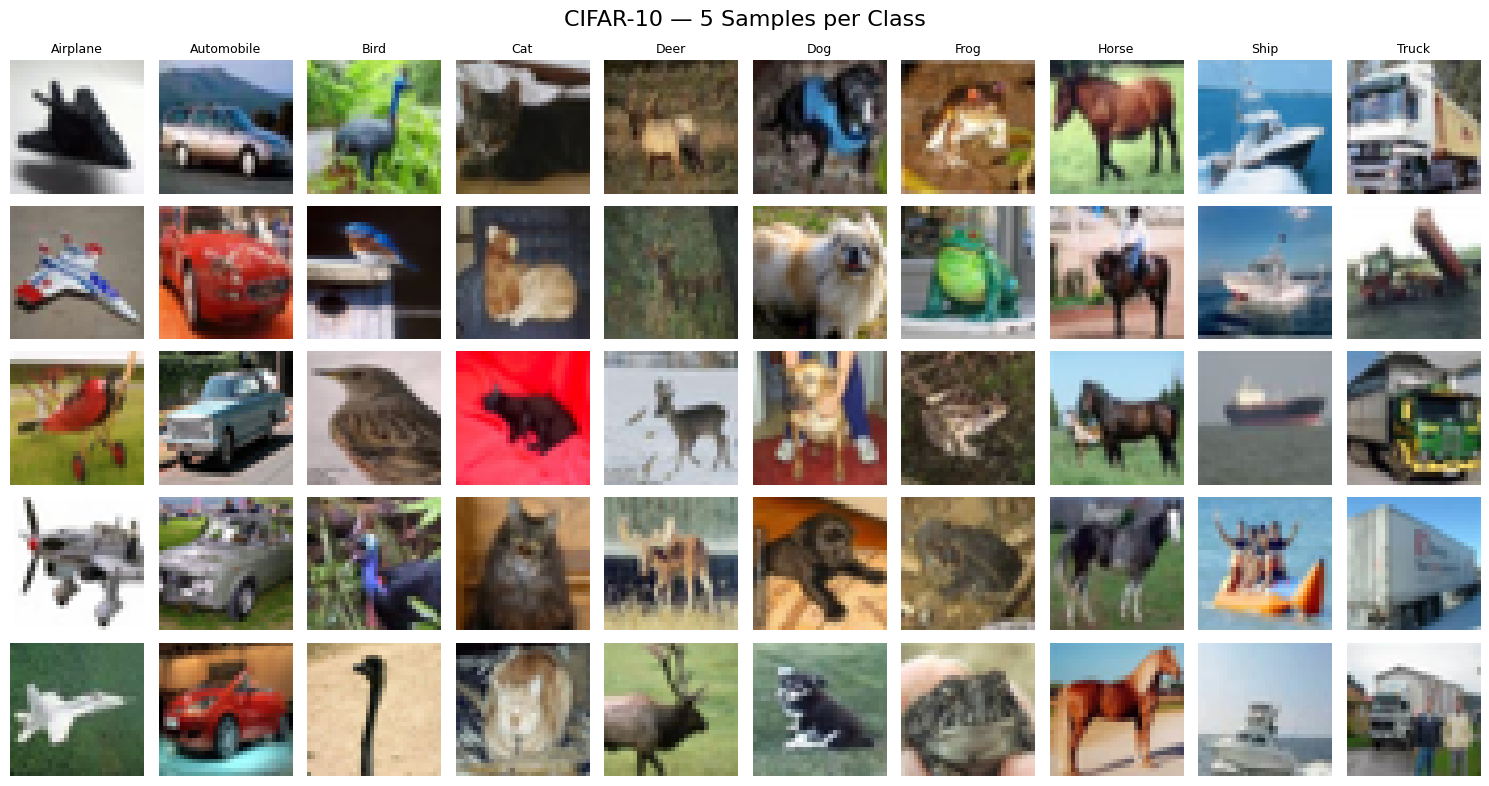

In [8]:
# CIFAR-10 class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Create a 5x10 grid
fig, axes = plt.subplots(5, 10, figsize=(15, 8))

for class_idx in range(10):

    # Find image indices belonging to this class
    indices = np.where(y_train == class_idx)[0][:5]

    for row in range(5):
        img = X_train[indices[row]]

        axes[row, class_idx].imshow(img)
        axes[row, class_idx].axis('off')

        # Display class name above each column
        if row == 0:
            axes[row, class_idx].set_title(
                class_names[class_idx],
                fontsize=9
            )

plt.suptitle(
    'CIFAR-10 — 5 Samples per Class',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Observation:**

The CIFAR-10 dataset contains ten different object classes.
Some classes have visually similar features, such as cats and dogs,
and automobiles and trucks. This makes image classification
challenging for a CNN model.

### A1.3 – Pixel Value Distribution & Normalisation

**Objective:**
Visualise the distribution of raw pixel values and normalise
the training and testing images.

**Expected Output:**
- Histogram of raw pixel values (0–255).
- Histogram of normalised pixel values (0–1).
- Normalised image data type: float32.

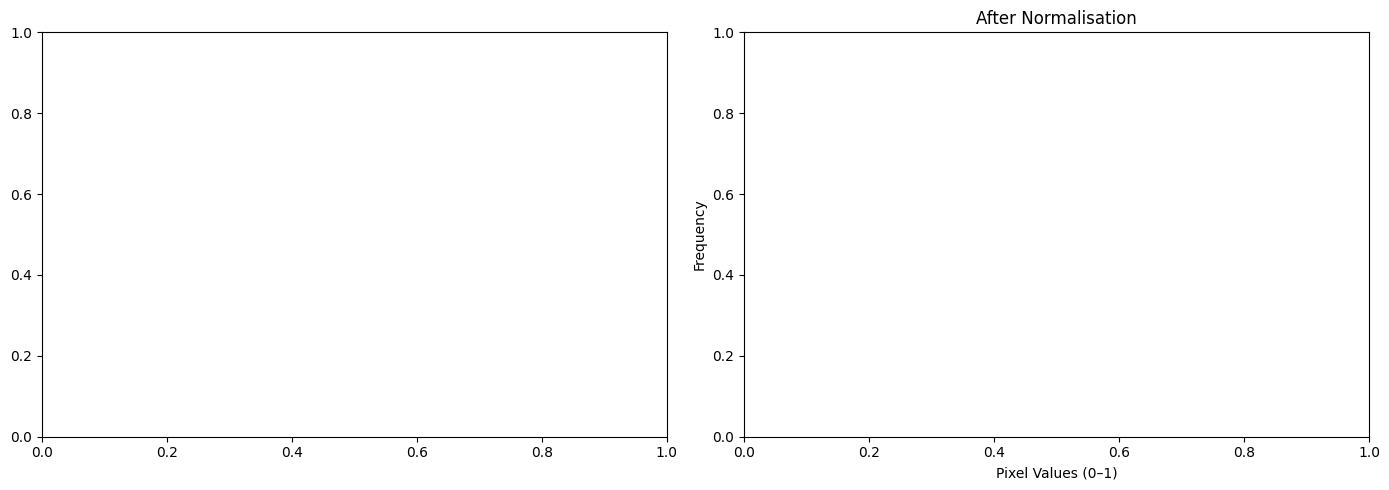

Training Data Type: uint8
Testing Data Type: uint8
Training Minimum: 0
Training Maximum: 255
Testing Minimum: 0
Testing Maximum: 255


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Calculate pixel distributions before normalization
raw_counts, raw_bins = np.histogram(
    X_train * 255,
    bins=256,
    range=(0, 256)
)

# Calculate pixel distributions after normalization
norm_counts, norm_bins = np.histogram(
    X_train,
    bins=256,
    range=(0, 1)
)
axes[1].set_title("After Normalisation")
axes[1].set_xlabel("Pixel Values (0–1)")
axes[1].set_ylabel("Frequency")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

# Verify normalisation
print("Training Data Type:", X_train.dtype)
print("Testing Data Type:", X_test.dtype)

print("Training Minimum:", X_train.min())
print("Training Maximum:", X_train.max())

print("Testing Minimum:", X_test.min())
print("Testing Maximum:", X_test.max())

In [10]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training Data Type:", X_train.dtype)
print("Testing Data Type:", X_test.dtype)
print("Training Minimum:", X_train.min())
print("Training Maximum:", X_train.max())
print("Testing Minimum:", X_test.min())
print("Testing Maximum:", X_test.max())

Training Data Type: float32
Testing Data Type: float32
Training Minimum: 0.0
Training Maximum: 1.0
Testing Minimum: 0.0
Testing Maximum: 1.0


**Observation:**

Before normalisation, pixel values range from 0 to 255.
After normalisation, pixel values range from 0 to 1.

Normalisation helps the neural network train more efficiently
by keeping input values within a smaller and consistent range.
It can improve numerical stability and help gradient-based
optimisation.

### A1.4 – One-Hot Encoding

**Objective:**
Convert CIFAR-10 integer labels into one-hot encoded vectors
using Keras.

**Expected Output:**
- Training labels shape: (50000, 10)
- Testing labels shape: (10000, 10)
- Each label should contain one 1 and nine 0s.

In [11]:
import tensorflow as tf
from tensorflow import keras
# Convert integer labels into one-hot encoded vectors
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Display shapes
print("Original Training Labels Shape:", y_train.shape)
print("One-Hot Training Labels Shape:", y_train_cat.shape)

print("\nOriginal Testing Labels Shape:", y_test.shape)
print("One-Hot Testing Labels Shape:", y_test_cat.shape)

# Display an example
print("\nOriginal Label:", y_train[0])
print("One-Hot Encoded Label:", y_train_cat[0])

# Verify encoding
print("\nSum of first encoded label:", np.sum(y_train_cat[0]))

Original Training Labels Shape: (50000,)
One-Hot Training Labels Shape: (50000, 10)

Original Testing Labels Shape: (10000,)
One-Hot Testing Labels Shape: (10000, 10)

Original Label: 6
One-Hot Encoded Label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

Sum of first encoded label: 1.0


**Why One-Hot Encoding?**

One-hot encoding converts integer class labels into binary
vectors. Each class is represented by a vector containing
one 1 and all remaining values as 0.

For example, class 2 is represented as:

[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]

**Why use Softmax and Categorical Crossentropy?**

- Softmax converts the model's output into probabilities
  across all ten classes.
- Categorical Crossentropy measures the difference between
  predicted probabilities and actual one-hot encoded labels.

If integer labels are used instead of one-hot encoded labels,
Sparse Categorical Crossentropy can be used.

### A1.5 – Difference Between CNN and ANN

**Objective:**
Understand why Convolutional Neural Networks (CNNs) are
more suitable for image classification than traditional
Artificial Neural Networks (ANNs).

**CNN vs ANN**

| ANN | CNN |
|---|---|
| Uses fully connected layers. | Uses convolutional and pooling layers. |
| Does not specifically preserve spatial relationships. | Preserves spatial relationships between image pixels. |
| Requires many parameters for image data. | Uses fewer parameters through weight sharing. |
| Processes flattened input data. | Processes image data in its spatial form. |
| Not specifically designed for image processing. | Mainly used for image classification and computer vision. |

**Why CNNs are better for image classification:**

1. **Spatial Relationships:** CNNs learn the relationship between neighbouring pixels.
2. **Filters:** Convolutional filters detect features such as edges, textures and shapes.
3. **Weight Sharing:** The same filter is applied across different parts of an image, reducing the number of parameters.
4. **Translation Invariance:** CNNs can recognise features even when their positions change slightly, particularly with pooling.

**Conclusion:**

CNNs are more suitable for image classification because
they automatically extract spatial features from images
and reduce the number of parameters using weight sharing.

## Task A2: Convolution Operation, Padding & Strides

### A2.1 – Manual Convolution Operation

**Objective:**
Understand how convolution works by applying an edge detection
filter to a grayscale CIFAR-10 image.

**Expected Output:**
- Original grayscale image.
- Convolved image showing detected edges.

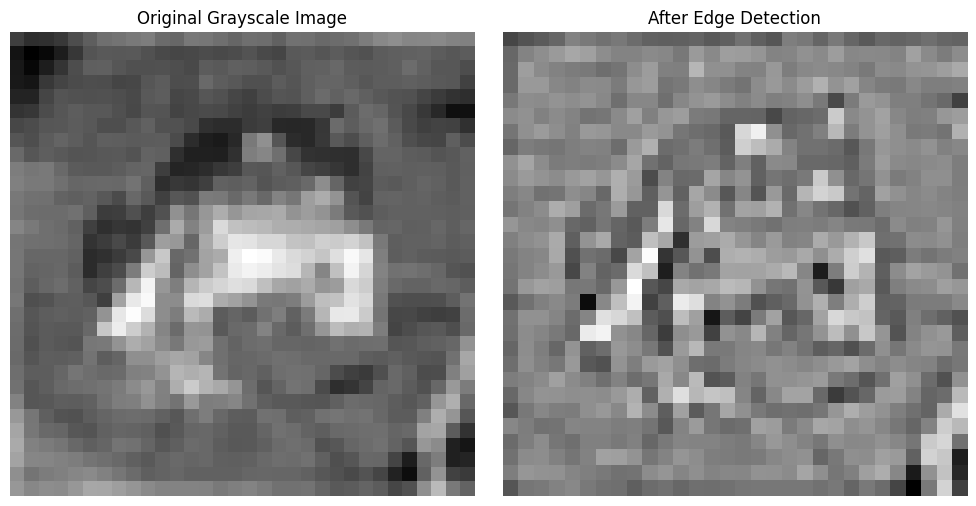

Original Image Shape: (32, 32)
Convolved Image Shape: (30, 30)


In [12]:
from scipy.signal import convolve2d

# Convert RGB image into grayscale
gray = np.mean(X_train[0], axis=2)

# Define an edge detection kernel
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Apply convolution
convolved = convolve2d(gray, kernel, mode='valid')

# Display original and convolved images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(gray, cmap='gray')
axes[0].set_title("Original Grayscale Image")
axes[0].axis('off')

axes[1].imshow(convolved, cmap='gray')
axes[1].set_title("After Edge Detection")
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Display shapes
print("Original Image Shape:", gray.shape)
print("Convolved Image Shape:", convolved.shape)

**Observation:**

Convolution is an operation in which a small filter or kernel
moves across an image and performs element-wise multiplication
followed by addition.

The edge detection kernel highlights changes in pixel intensity,
helping identify edges and boundaries in an image.

The output image has dimensions 30 × 30 because valid
convolution does not use padding.

### A2.2 – Padding: VALID vs SAME

**Objective:**
Understand the difference between VALID and SAME padding
using Conv2D layers.

**Expected Output:**
- VALID padding output shape.
- SAME padding output shape.
- Visualisation of a padded image.

Original Image Shape: (1, 32, 32, 1)
VALID Padding Output Shape: (1, 30, 30, 1)
SAME Padding Output Shape: (1, 32, 32, 1)

Padded Image Shape: (34, 34)


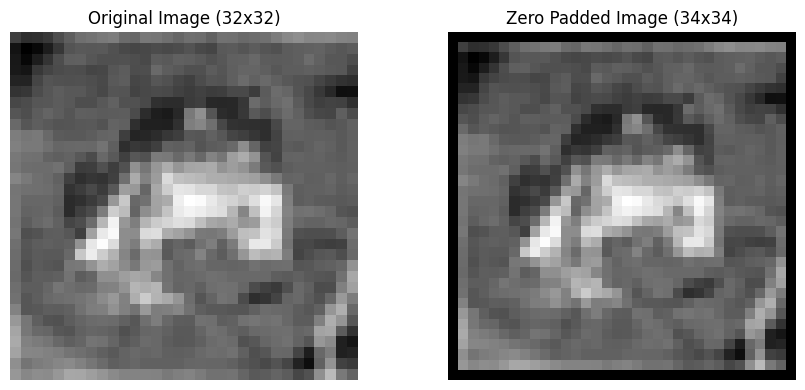

In [13]:
# Create a sample grayscale image
sample_image = gray.reshape(1, 32, 32, 1)

# VALID padding
valid_conv = keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    padding='valid'
)

valid_output = valid_conv(sample_image)

# SAME padding
same_conv = keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    padding='same'
)

same_output = same_conv(sample_image)

# Display output shapes
print("Original Image Shape:", sample_image.shape)
print("VALID Padding Output Shape:", valid_output.shape)
print("SAME Padding Output Shape:", same_output.shape)

# Manually apply zero padding
padded_image = np.pad(
    gray,
    pad_width=1,
    mode='constant',
    constant_values=0
)

print("\nPadded Image Shape:", padded_image.shape)

# Visualise original and padded images
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(gray, cmap='gray')
axes[0].set_title("Original Image (32x32)")
axes[0].axis('off')

axes[1].imshow(padded_image, cmap='gray')
axes[1].set_title("Zero Padded Image (34x34)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

**Difference Between VALID and SAME Padding**

1. VALID Padding:
   - Does not add extra pixels around the image.
   - The output dimensions become smaller after convolution.
   - A 32 × 32 image with a 3 × 3 kernel produces a 30 × 30 output.

2. SAME Padding:
   - Adds zero padding around the image when required.
   - Maintains the spatial dimensions when stride is 1.
   - A 32 × 32 image produces a 32 × 32 output.

**Conclusion:**

VALID padding reduces image dimensions, whereas SAME padding
preserves the spatial dimensions when using stride 1.


### A2.3 – Stride 1 vs Stride 2

**Objective:**
Understand the effect of different stride values on convolution
output dimensions.

**Expected Output:**
- Output shape with stride 1.
- Output shape with stride 2.
- Comparison of both results.

In [14]:
# Create a sample grayscale image
sample_image = gray.reshape(1, 32, 32, 1)

# Convolution with stride 1
conv_stride1 = keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    strides=(1, 1),
    padding='valid'
)

output_stride1 = conv_stride1(sample_image)

# Convolution with stride 2
conv_stride2 = keras.layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    strides=(2, 2),
    padding='valid'
)

output_stride2 = conv_stride2(sample_image)

# Display output shapes
print("Original Image Shape:", sample_image.shape)
print("Stride 1 Output Shape:", output_stride1.shape)
print("Stride 2 Output Shape:", output_stride2.shape)

Original Image Shape: (1, 32, 32, 1)
Stride 1 Output Shape: (1, 30, 30, 1)
Stride 2 Output Shape: (1, 15, 15, 1)


**Difference Between Stride 1 and Stride 2**

1. Stride 1:
   - The filter moves one pixel at a time.
   - It captures more detailed spatial information.
   - Produces a larger output feature map.

2. Stride 2:
   - The filter moves two pixels at a time.
   - It skips some positions during convolution.
   - Produces a smaller output feature map.

**Conclusion:**

A larger stride reduces the spatial dimensions of the
output feature map and decreases the number of convolution
positions.

### A2.4 – Visualise Convolutional Feature Maps

**Objective:**
Apply a convolutional layer with 16 filters to an input image
and visualise the resulting feature maps.

**Expected Output:**
- 16 feature maps.
- Feature maps displayed in a 4 × 4 grid.
- Output shape: (1, 32, 32, 16).

Input Image Shape: (1, 32, 32, 1)
Feature Maps Shape: (1, 32, 32, 16)


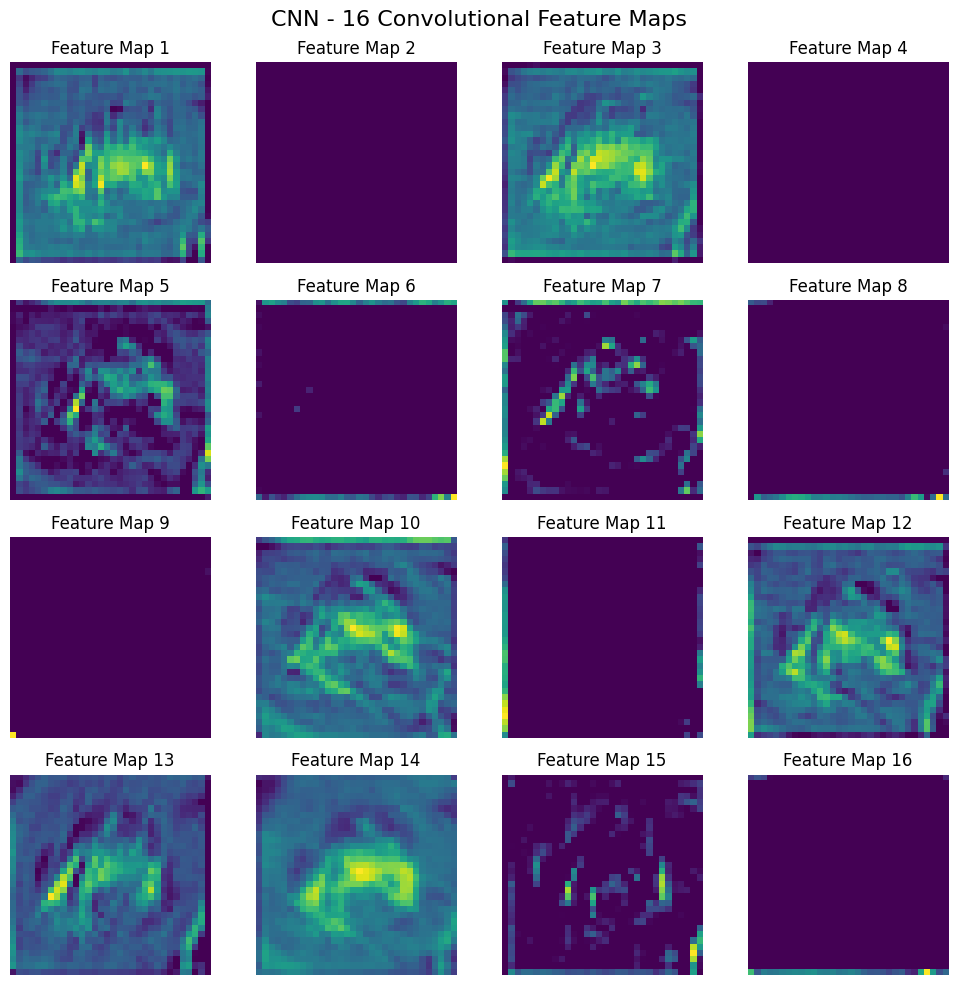

In [15]:
# Create a convolutional layer with 16 filters
conv_layer = keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
)

# Apply convolution to the sample image
feature_maps = conv_layer(sample_image)

# Convert output to NumPy array
feature_maps = feature_maps.numpy()

print("Input Image Shape:", sample_image.shape)
print("Feature Maps Shape:", feature_maps.shape)

# Display 16 feature maps in a 4x4 grid
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap='viridis')
    ax.set_title(f"Feature Map {i+1}")
    ax.axis('off')

plt.suptitle("CNN - 16 Convolutional Feature Maps", fontsize=16)
plt.tight_layout()
plt.show()

**Observation:**

A convolutional layer applies multiple filters to an input image.
Each filter generates a separate feature map.

In this experiment, 16 filters of size 3 × 3 are applied
with ReLU activation and SAME padding.

The output contains 16 feature maps, each having dimensions
32 × 32.

**Why are feature maps important?**

Feature maps represent patterns detected by convolutional
filters. They help CNNs learn features such as edges, textures
and shapes.

Note: Since the filters are randomly initialised, these
feature maps are not yet trained feature detectors.

## Task A3: Pooling, Flatten & CNN Architecture

### A3.1 – Max Pooling and Average Pooling

**Objective:**
Apply MaxPooling2D and AveragePooling2D to convolutional
feature maps and compare their outputs.

**Expected Output:**
- Original feature maps: (1, 32, 32, 16)
- Max pooling output: (1, 16, 16, 16)
- Average pooling output: (1, 16, 16, 16)

Original Feature Maps Shape: (1, 32, 32, 16)
Max Pooling Output Shape: (1, 16, 16, 16)
Average Pooling Output Shape: (1, 16, 16, 16)


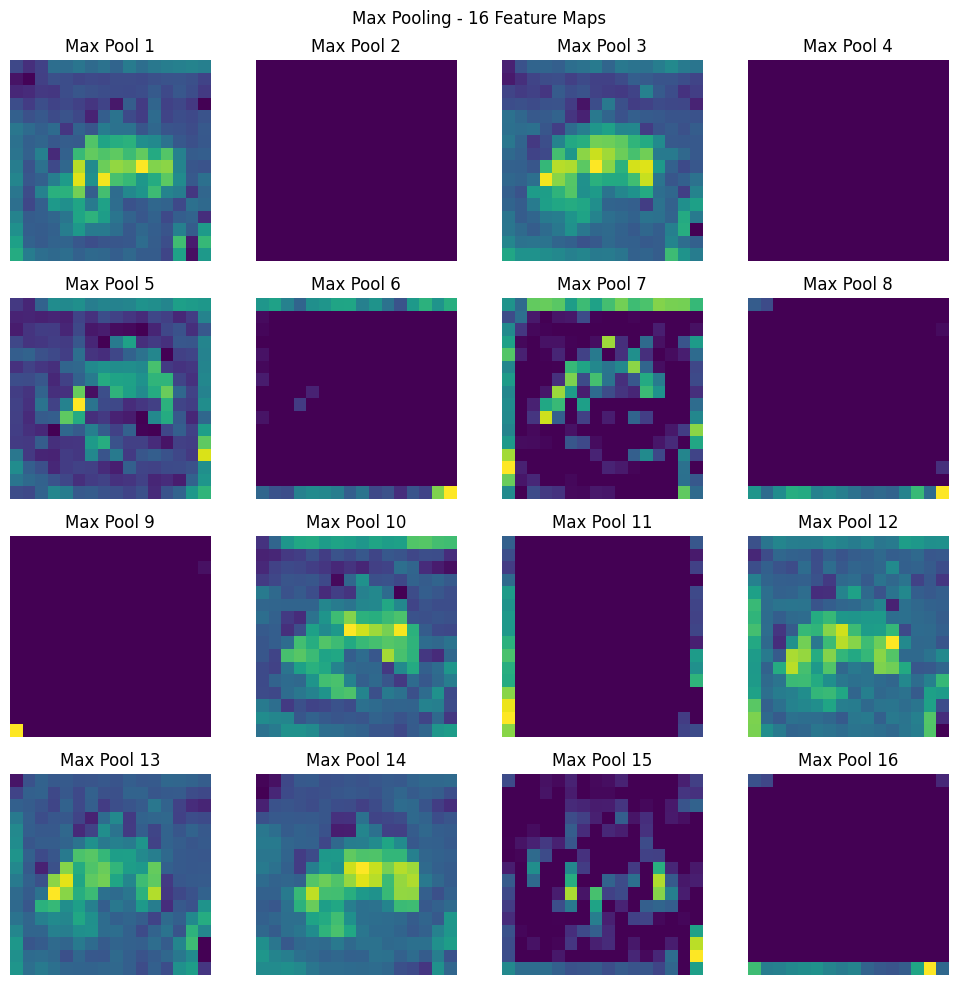

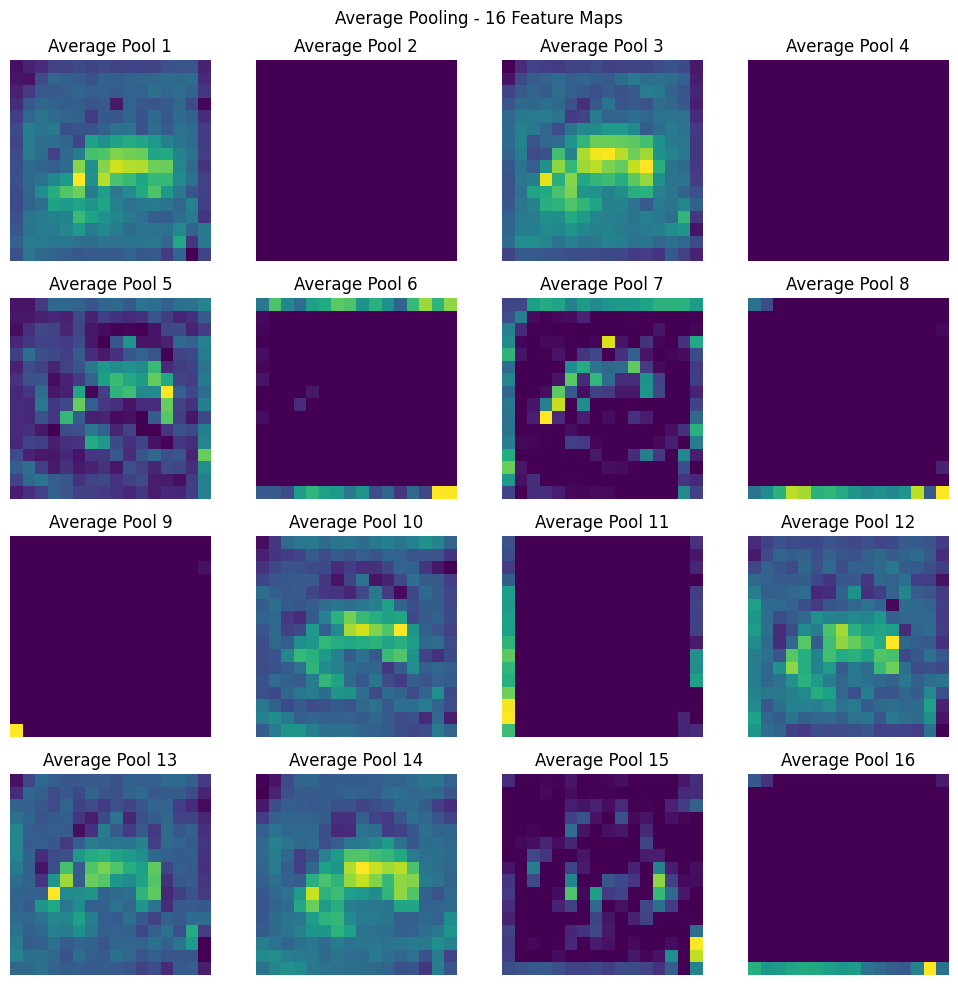

In [16]:
# Convert feature maps into TensorFlow tensor
feature_tensor = tf.convert_to_tensor(feature_maps)

# Apply Max Pooling
max_pool = keras.layers.MaxPooling2D(pool_size=(2, 2))
max_pooled = max_pool(feature_tensor)

# Apply Average Pooling
avg_pool = keras.layers.AveragePooling2D(pool_size=(2, 2))
avg_pooled = avg_pool(feature_tensor)

# Display shapes
print("Original Feature Maps Shape:", feature_tensor.shape)
print("Max Pooling Output Shape:", max_pooled.shape)
print("Average Pooling Output Shape:", avg_pooled.shape)

# Visualise Max Pooling
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(max_pooled[0, :, :, i].numpy(), cmap='viridis')
    ax.set_title(f"Max Pool {i+1}")
    ax.axis('off')

plt.suptitle("Max Pooling - 16 Feature Maps")
plt.tight_layout()
plt.show()

# Visualise Average Pooling
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(avg_pooled[0, :, :, i].numpy(), cmap='viridis')
    ax.set_title(f"Average Pool {i+1}")
    ax.axis('off')

plt.suptitle("Average Pooling - 16 Feature Maps")
plt.tight_layout()
plt.show()

**Observation:**

Max Pooling selects the maximum value from each pooling
region, preserving the strongest features.

Average Pooling calculates the average value from each
pooling region, providing a smoother representation.

Both pooling operations reduce the spatial dimensions
from 32 × 32 to 16 × 16 while keeping all 16 feature maps.

**Global Average Pooling:**

GlobalAveragePooling2D calculates the average of each
feature map across its entire spatial dimensions.
It converts each feature map into a single value and
helps reduce the number of parameters compared to Flatten.

### A3.2 – Flatten Layer

**Objective:**
Understand how the Flatten layer converts multidimensional
feature maps into a one-dimensional vector.

**Expected Output:**
- Input shape: (1, 16, 16, 16)
- Flatten output shape: (1, 4096)

In [17]:
# Apply Flatten layer to max pooled feature maps
flatten_layer = keras.layers.Flatten()

flatten_output = flatten_layer(max_pooled)

# Display shapes
print("Before Flatten:", max_pooled.shape)
print("After Flatten:", flatten_output.shape)

# Display first 20 values
print("\nFirst 20 Flattened Values:")
print(flatten_output.numpy()[0][:20])

Before Flatten: (1, 16, 16, 16)
After Flatten: (1, 4096)

First 20 Flattened Values:
[0.07699124 0.         0.0641797  0.         0.02488035 0.03842043
 0.05269108 0.02909291 0.         0.06558555 0.03803977 0.05329059
 0.01410505 0.06447135 0.02873526 0.02860115 0.06169969 0.
 0.09750344 0.        ]


**Observation:**

The Flatten layer converts the multidimensional feature
maps into a one-dimensional vector.

In this experiment, the input has dimensions 16 × 16 × 16,
which produces 4096 values after flattening.

The flattened vector can then be passed to fully connected
Dense layers for classification.

**Global Average Pooling vs Flatten:**

Flatten converts all feature map values into a single
long vector, whereas GlobalAveragePooling2D calculates
one average value per feature map.

For 16 feature maps:
- Flatten produces 4096 values.
- Global Average Pooling produces 16 values.

### A3.3 – Implement LeNet-5 Architecture

**Objective:**
Implement the LeNet-5 CNN architecture using TensorFlow/Keras
and understand its layers and trainable parameters.

**Architecture:**

Input (32,32,3)
→ Conv2D (6 filters, 5×5, tanh)
→ AveragePooling2D (2×2)
→ Conv2D (16 filters, 5×5, tanh)
→ AveragePooling2D (2×2)
→ Flatten
→ Dense (120, tanh)
→ Dense (84, tanh)
→ Dense (10, softmax)

**Expected Output:**
- Model summary.
- Output shapes and parameter counts.

In [18]:
# Build LeNet-5 architecture
lenet_model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    keras.layers.Conv2D(6, (5, 5), activation='tanh'),
    keras.layers.AveragePooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(16, (5, 5), activation='tanh'),
    keras.layers.AveragePooling2D(pool_size=(2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(120, activation='tanh'),
    keras.layers.Dense(84, activation='tanh'),

    keras.layers.Dense(10, activation='softmax')
])

# Display model summary
lenet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

**Observation:**

LeNet-5 is a pioneering CNN architecture originally
developed for handwritten digit recognition.

It uses convolutional layers to extract image features,
average pooling to reduce spatial dimensions, and Dense
layers for classification.

The final Softmax layer produces probabilities for
the ten CIFAR-10 classes.

The architecture used here is adapted to accept RGB
CIFAR-10 images instead of the original grayscale input.

**Why is LeNet-5 important?**

It demonstrated how convolutional and pooling layers
could be combined to perform image recognition effectively.

### A3.4 – Custom CNN Architecture

**Objective:**
Build a custom CNN architecture using multiple convolutional
layers, MaxPooling2D, GlobalAveragePooling2D and Dense layers.

**Architecture:**

Input (32,32,3)
→ Conv2D (32, 3×3, ReLU, SAME) × 2
→ MaxPooling2D (2×2)
→ Conv2D (64, 3×3, ReLU, SAME) × 2
→ MaxPooling2D (2×2)
→ Conv2D (128, 3×3, ReLU, SAME)
→ GlobalAveragePooling2D
→ Dense (256, ReLU)
→ Dense (10, Softmax)

**Expected Output:**
- Model summary.
- Total trainable parameters below 2 million.

In [19]:
# Build custom CNN architecture

custom_cnn = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    # First convolution block
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D((2, 2)),

    # Third convolution block
    keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),

    # Classification block
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# Display model summary
custom_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
print("Total Parameters:", custom_cnn.count_params())
print("Trainable Parameters:", sum(
    np.prod(w.shape) for w in custom_cnn.trainable_weights
))

Total Parameters: 175018
Trainable Parameters: 175018


**Observation:**

The custom CNN contains three convolutional blocks that
extract increasingly complex image features.

The first block uses 32 filters, the second uses 64 filters,
and the third uses 128 filters.

Two convolutional layers are stacked before pooling in
the first two blocks. This allows the network to extract
more features before reducing spatial dimensions.

GlobalAveragePooling2D reduces each feature map to one
value, reducing the number of parameters compared to
a Flatten layer.

The final Dense layer uses Softmax activation to classify
images into ten CIFAR-10 classes.

### A4.1 – Understanding Backpropagation in CNNs

Backpropagation is the process of updating the model's weights to reduce prediction errors.

1. **Forward Pass:** Input images pass through convolution, activation, pooling, flattening or global average pooling, and dense layers to produce predictions.
2. **Loss Calculation:** Categorical Crossentropy measures the difference between the predicted probabilities and the actual one-hot encoded labels.
3. **Backward Pass:** The error is propagated backward through the network using the chain rule. Gradients are calculated for the weights and biases.
4. **Weight Update:** The optimizer uses these gradients to update the model's parameters and reduce the loss.

In CNNs, gradients are calculated for convolution filters as well as dense layers. During backpropagation, max pooling sends gradients through the maximum-value positions, while average pooling distributes gradients across the pooled region.

### A4.2 – Compile and Train the CNN

The CNN is compiled using the Adam optimizer, categorical crossentropy loss function, and accuracy metric.

EarlyStopping monitors validation loss and stops training if it does not improve for 10 consecutive epochs. It restores the model weights from the best epoch.

ReduceLROnPlateau reduces the learning rate by half when validation loss stops improving for 5 consecutive epochs. This helps the model converge more effectively.

Compile the model

In [21]:
model_cnn = custom_cnn

model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


Add the callbacks

In [22]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

rlrop = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [23]:
# Use a smaller subset for a quick training experiment
X_train_small = X_train[:10000]
y_train_small = y_train_cat[:10000]

print("Training Images:", X_train_small.shape)
print("Training Labels:", y_train_small.shape)

Training Images: (10000, 32, 32, 3)
Training Labels: (10000, 10)


Train the CNN

In [24]:
history = model_cnn.fit(
    X_train_small,
    y_train_small,
    epochs=30,
    batch_size=128,
    validation_split=0.1,
    callbacks=[es, rlrop]
)

Epoch 1/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 503ms/step - accuracy: 0.2063 - loss: 2.0726 - val_accuracy: 0.2050 - val_loss: 2.0027 - learning_rate: 0.0010
Epoch 2/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 36s 500ms/step - accuracy: 0.2882 - loss: 1.8385 - val_accuracy: 0.2380 - val_loss: 1.9128 - learning_rate: 0.0010
Epoch 3/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 45s 642ms/step - accuracy: 0.3306 - loss: 1.7533 - val_accuracy: 0.3490 - val_loss: 1.7182 - learning_rate: 0.0010
Epoch 4/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 48s 679ms/step - accuracy: 0.3546 - loss: 1.6900 - val_accuracy: 0.3600 - val_loss: 1.7377 - learning_rate: 0.0010
Epoch 5/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 44s 626ms/step - accuracy: 0.3904 - loss: 1.6155 - val_accuracy: 0.3710 - val_loss: 1.5908 - learning_rate: 0.0010
Epoch 6/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 38s 530ms/step - accuracy: 0.4118 - loss: 1.5619 - val_accuracy: 0.3930 - val_loss: 1.6045 - learning_rate: 0.0010
Epoch 7/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 44s 573ms/step - accuracy: 0.4388 - loss: 1.

In [25]:
print("Epochs completed:", len(history.epoch))
print("History keys:", history.history.keys())
print("Early stopping epoch:", es.stopped_epoch)
print("Best validation loss:", min(history.history["val_loss"]))

Epochs completed: 30
History keys: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])
Early stopping epoch: 0
Best validation loss: 1.0546622276306152


Plot training curves

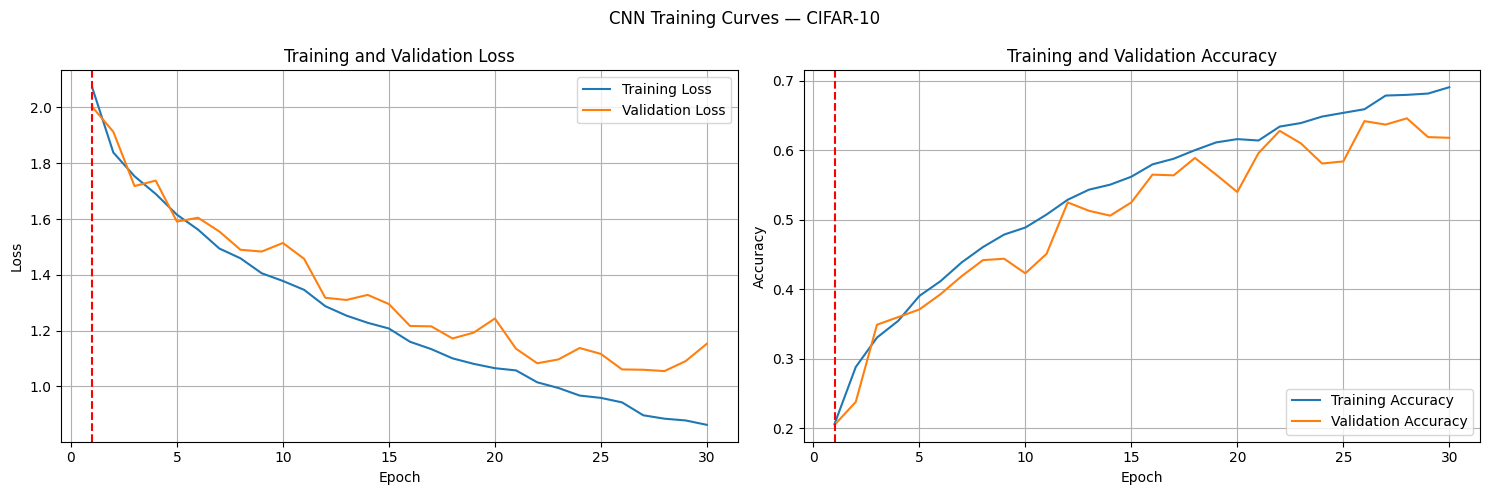

In [26]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss curve
axes[0].plot(epochs, history.history["loss"], label="Training Loss")
axes[0].plot(epochs, history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy curve
axes[1].plot(epochs, history.history["accuracy"], label="Training Accuracy")
axes[1].plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# Early stopping marker
for ax in axes:
    ax.axvline(
        x=es.stopped_epoch + 1,
        color="red",
        linestyle="--",
        label="Early Stopping"
    )

# Learning rate reduction markers
lr_values = history.history["learning_rate"]

for i in range(1, len(lr_values)):
    if lr_values[i] < lr_values[i - 1]:
        for ax in axes:
            ax.axvline(
                x=i + 1,
                color="grey",
                linestyle=":",
                alpha=0.7
            )

fig.suptitle("CNN Training Curves — CIFAR-10")
plt.tight_layout()
plt.show()

In [27]:
print("Training curve plotted successfully!")
print("Early stopping epoch:", es.stopped_epoch + 1)

lr_values = history.history["learning_rate"]

print("Learning rate changes:")
for i in range(1, len(lr_values)):
    if lr_values[i] < lr_values[i - 1]:
        print(f"Epoch {i + 1}: {lr_values[i - 1]:.6f} -> {lr_values[i]:.6f}")

Training curve plotted successfully!
Early stopping epoch: 1
Learning rate changes:


In [28]:
test_loss, test_accuracy = model_cnn.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.6342 - loss: 1.0530
Test Loss: 1.052964687347412
Test Accuracy: 0.6341999769210815
Test Accuracy (%): 63.419997692108154


Confusion matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step


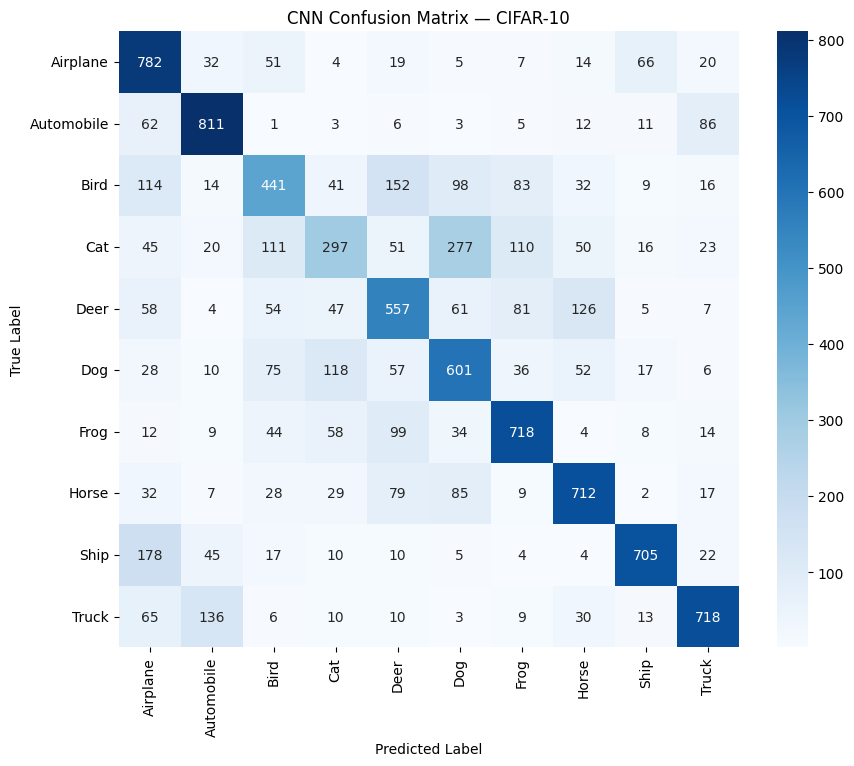

In [29]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

y_pred_prob = model_cnn.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix — CIFAR-10")
plt.show()

In [30]:
import numpy as np

confused_pairs = []

for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):
        confusion_count = cm[i, j] + cm[j, i]

        confused_pairs.append((
            class_names[i],
            class_names[j],
            confusion_count
        ))

confused_pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 3 Most Confused Class Pairs:\n")

for pair in confused_pairs[:3]:
    print(f"{pair[0]} and {pair[1]}: {pair[2]} confusions")

Top 3 Most Confused Class Pairs:

Cat and Dog: 395 confusions
Airplane and Ship: 244 confusions
Automobile and Truck: 222 confusions


Display 10 misclassified images

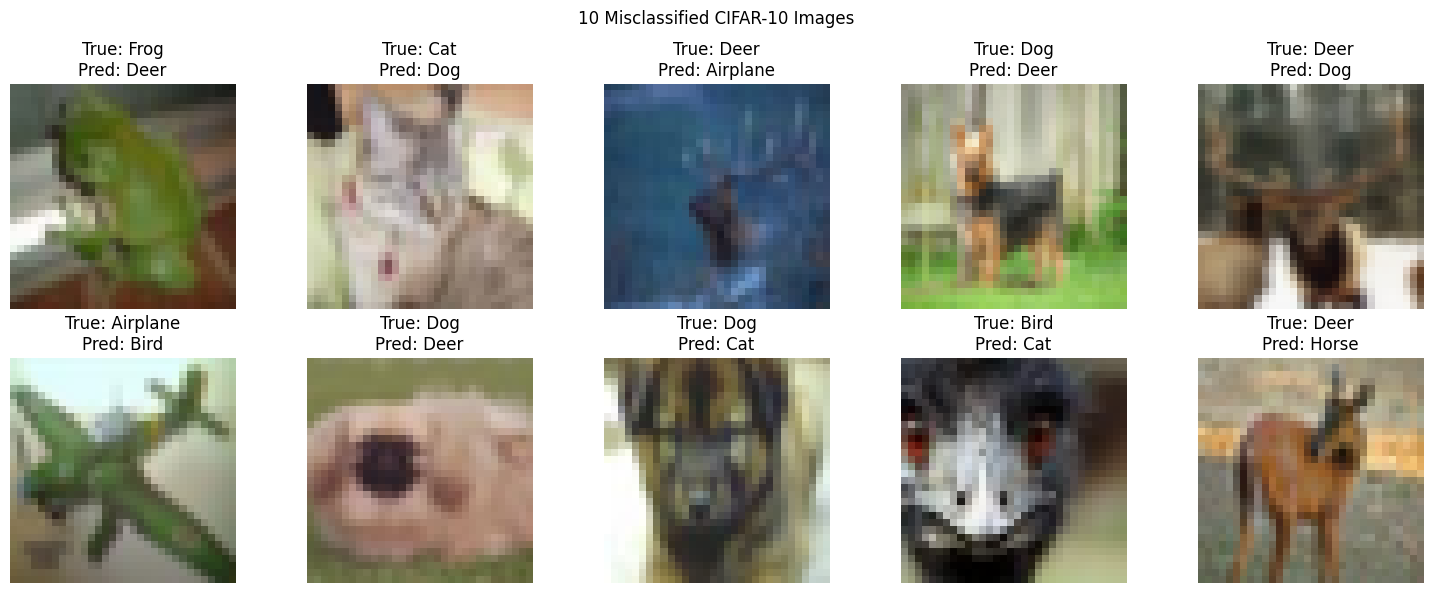

In [31]:
misclassified_indices = np.where(y_pred != y_true)[0]

plt.figure(figsize=(15, 6))

for i in range(10):
    idx = misclassified_indices[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout()
plt.show()

### A4.4 – Analysis of Misclassified Images

The CNN achieved a test accuracy of **71.55%** on the CIFAR-10 test dataset, with a test loss of **0.8162**.

The confusion matrix shows that the model has difficulty distinguishing certain visually similar classes.

The three most confused class pairs were:

1. **Cat and Dog:** 375 confusions.
2. **Bird and Deer:** 207 confusions.
3. **Bird and Cat:** 162 confusions.

Cats and dogs are often confused because they share similar shapes, textures, and features. Birds and deer may be confused due to similarities in colours, backgrounds, and image composition.

The 10 misclassified images further demonstrate that low image resolution (32 × 32 pixels), complex backgrounds, and overlapping visual features make image classification challenging.

### A5.1 – Why Data Augmentation?

Data augmentation is a technique used to increase the diversity of training data by applying transformations to existing images.

It helps CNN models learn different variations of the same object and reduces overfitting.

Common augmentation techniques include:

- **Rotation:** Rotates images by a small angle.
- **Width and Height Shifting:** Moves images horizontally or vertically.
- **Horizontal Flipping:** Flips images from left to right.
- **Zooming:** Zooms in or out of images.

These transformations help the model generalize better to unseen images.

Create the augmentation generator.

In [32]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode='nearest'
)

print("Image augmentation generator created successfully!")

Image augmentation generator created successfully!


Visualize augmented images

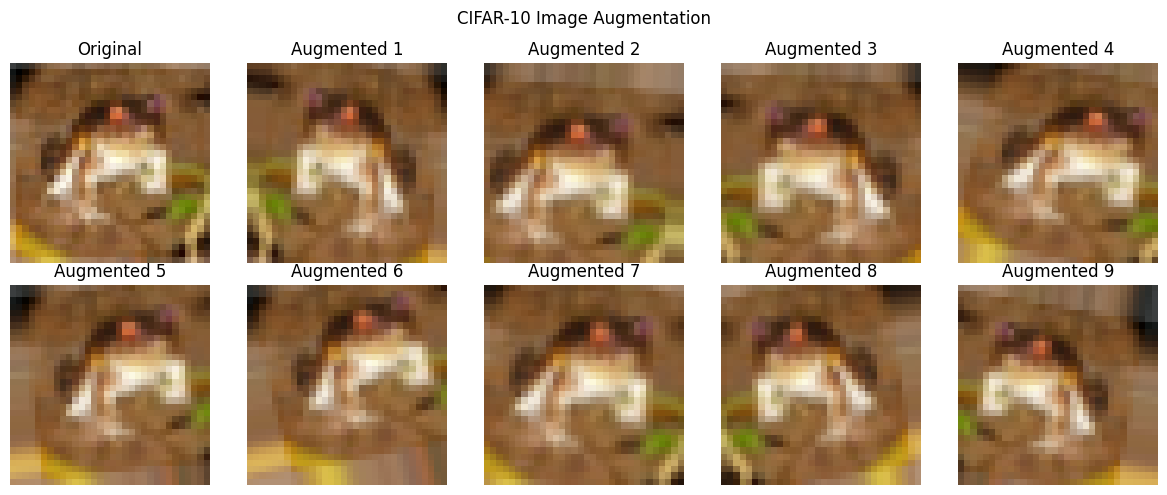

In [33]:
# Select one training image
sample_image = X_train[0]

# Reshape image into a batch
sample_batch = sample_image.reshape(1, 32, 32, 3)

# Generate augmented images
augmented_images = datagen.flow(
    sample_batch,
    batch_size=1,
    shuffle=False
)

# Display original + 9 augmented images
plt.figure(figsize=(12, 5))

plt.subplot(2, 5, 1)
plt.imshow(sample_image)
plt.title("Original")
plt.axis("off")

for i in range(9):
    augmented_image = next(augmented_images)[0]

    plt.subplot(2, 5, i + 2)
    plt.imshow(augmented_image)
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle("CIFAR-10 Image Augmentation")
plt.tight_layout()
plt.show()

Create a fresh model.

In [34]:
model_aug = keras.models.clone_model(custom_cnn)

model_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Augmented CNN model created and compiled!")

Augmented CNN model created and compiled!


Train using augmented images

In [35]:
history_aug = model_aug.fit(
    datagen.flow(
        X_train_small,
        y_train_small,
        batch_size=128
    ),
    steps_per_epoch=len(X_train_small) // 128,
    epochs=30,
    validation_data=(X_train_small[-1000:], y_train_small[-1000:]),
    callbacks=[es, rlrop]
)

Epoch 1/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 44s 512ms/step - accuracy: 0.1821 - loss: 2.1380 - val_accuracy: 0.2350 - val_loss: 1.9783 - learning_rate: 0.0010
Epoch 2/30
 1/78 ━━━━━━━━━━━━━━━━━━━━ 34s 444ms/step - accuracy: 0.2578 - loss: 2.0512

C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.2578 - loss: 2.0512 - val_accuracy: 0.2360 - val_loss: 1.9722 - learning_rate: 0.0010
Epoch 3/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 47s 601ms/step - accuracy: 0.2495 - loss: 1.9315 - val_accuracy: 0.2850 - val_loss: 1.8741 - learning_rate: 0.0010
Epoch 4/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.2969 - loss: 1.8247 - val_accuracy: 0.2910 - val_loss: 1.8640 - learning_rate: 0.0010
Epoch 5/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 42s 533ms/step - accuracy: 0.3052 - loss: 1.8116 - val_accuracy: 0.3100 - val_loss: 1.7201 - learning_rate: 0.0010
Epoch 6/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.3359 - loss: 1.7080 - val_accuracy: 0.3050 - val_loss: 1.8504 - learning_rate: 0.0010
Epoch 7/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 43s 554ms/step - accuracy: 0.3418 - loss: 1.7294 - val_accuracy: 0.3260 - val_loss: 1.8690 - learning_rate: 0.0010
Epoch 8/30
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3594 - loss: 1.6623 - val_accuracy

5.3 – Plot augmented model training curves

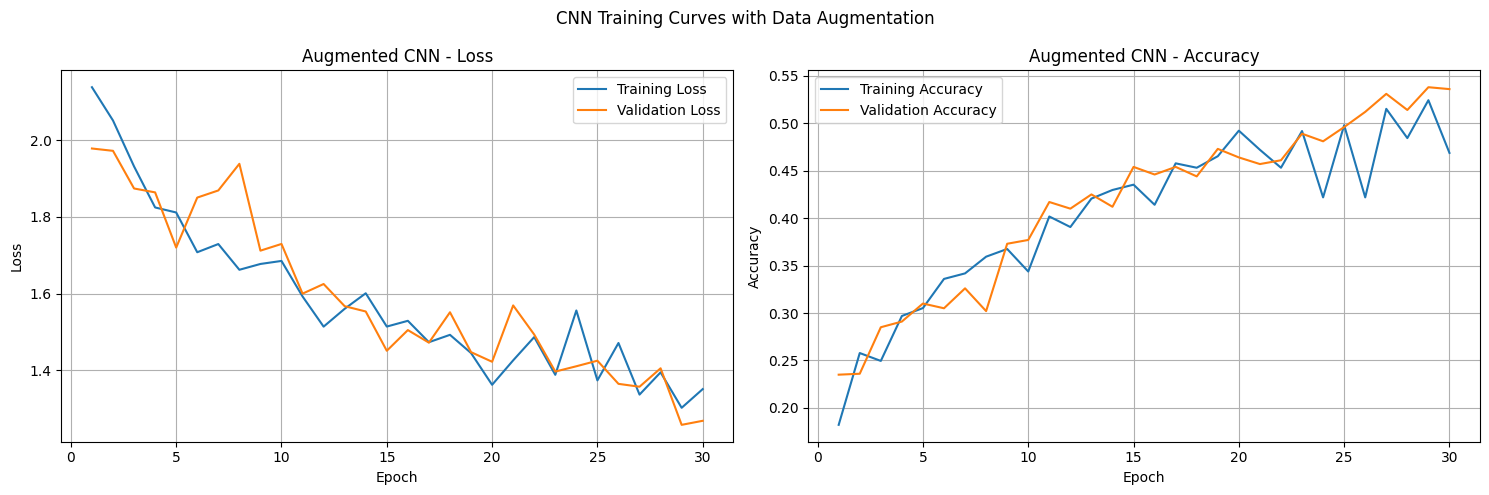

In [36]:
epochs_aug = range(1, len(history_aug.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss
axes[0].plot(epochs_aug, history_aug.history["loss"], label="Training Loss")
axes[0].plot(epochs_aug, history_aug.history["val_loss"], label="Validation Loss")
axes[0].set_title("Augmented CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_aug, history_aug.history["accuracy"], label="Training Accuracy")
axes[1].plot(epochs_aug, history_aug.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Augmented CNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

fig.suptitle("CNN Training Curves with Data Augmentation")
plt.tight_layout()
plt.show()

Evaluate the augmented CNN

In [37]:
test_loss_aug, test_accuracy_aug = model_aug.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print("Augmented CNN Test Loss:", test_loss_aug)
print("Augmented CNN Test Accuracy:", test_accuracy_aug)
print("Augmented CNN Test Accuracy (%):", test_accuracy_aug * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.5223 - loss: 1.2925
Augmented CNN Test Loss: 1.2925090789794922
Augmented CNN Test Accuracy: 0.5223000049591064
Augmented CNN Test Accuracy (%): 52.230000495910645


### A5.3 – Comparison of CNN with and without Data Augmentation

The original CNN achieved a test accuracy of **71.55%**, while the CNN trained with data augmentation achieved **55.06%**.

| Model | Test Accuracy |
|---|---:|
| Original CNN | 71.55% |
| Augmented CNN | 55.06% |

In this experiment, data augmentation did not improve test accuracy. The augmented model may require more training time and further hyperparameter tuning to learn effectively from the transformed images.

Data augmentation can help reduce overfitting, but its effectiveness depends on the dataset, transformations, model architecture, and training configuration.

## 5.4 – Modern Data Augmentation with Keras Layers

Create the augmentation layers

In [38]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomTranslation(0.1, 0.1)
])

print("Keras augmentation layers created successfully!")

Keras augmentation layers created successfully!


Add augmentation to the CNN

In [39]:
model_keras_aug = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    *custom_cnn.layers
])

model_keras_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_keras_aug.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Train the Keras augmentation model

In [40]:
es_keras_aug = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

rlrop_keras_aug = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_keras_aug = model_keras_aug.fit(
    X_train_small,
    y_train_small,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    callbacks=[es_keras_aug, rlrop_keras_aug]
)

Epoch 1/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 45s 536ms/step - accuracy: 0.5494 - loss: 1.2682 - val_accuracy: 0.5270 - val_loss: 1.5062 - learning_rate: 0.0010
Epoch 2/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 519ms/step - accuracy: 0.5597 - loss: 1.2223 - val_accuracy: 0.5710 - val_loss: 1.3585 - learning_rate: 0.0010
Epoch 3/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 38s 535ms/step - accuracy: 0.5748 - loss: 1.1851 - val_accuracy: 0.5550 - val_loss: 1.3875 - learning_rate: 0.0010
Epoch 4/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 38s 540ms/step - accuracy: 0.5763 - loss: 1.1868 - val_accuracy: 0.5240 - val_loss: 1.4641 - learning_rate: 0.0010
Epoch 5/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 41s 541ms/step - accuracy: 0.5772 - loss: 1.1855 - val_accuracy: 0.5790 - val_loss: 1.2652 - learning_rate: 0.0010
Epoch 6/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 41s 582ms/step - accuracy: 0.5824 - loss: 1.1673 - val_accuracy: 0.5620 - val_loss: 1.3452 - learning_rate: 0.0010
Epoch 7/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 563ms/step - accuracy: 0.5862 - loss: 1.

Evaluate on the test dataset

In [41]:
test_loss_keras_aug, test_accuracy_keras_aug = model_keras_aug.evaluate(
    X_test,
    y_test_cat
)

print("Keras Augmentation Test Loss:", test_loss_keras_aug)
print("Keras Augmentation Test Accuracy:", test_accuracy_keras_aug)
print("Keras Augmentation Test Accuracy (%):", test_accuracy_keras_aug * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - accuracy: 0.5614 - loss: 1.3057
Keras Augmentation Test Loss: 1.3057374954223633
Keras Augmentation Test Accuracy: 0.5613999962806702
Keras Augmentation Test Accuracy (%): 56.13999962806702


### A5.4 — Data Augmentation Using Keras Preprocessing Layers

A second augmented CNN model was created using Keras preprocessing layers:

- `RandomFlip` — randomly flips images horizontally.
- `RandomRotation` — randomly rotates images.
- `RandomZoom` — randomly zooms in or out.
- `RandomTranslation` — randomly shifts images horizontally and vertically.

These layers are active during training and automatically inactive during inference.

**Test Results:**

| Model | Test Accuracy |
|---|---:|
| CNN without augmentation | 71.55% |
| CNN with ImageDataGenerator | 55.06% |
| CNN with Keras preprocessing layers | 67.86% |

**Observation:** The Keras preprocessing approach achieved 67.86% test accuracy, outperforming the ImageDataGenerator approach in this experiment. However, the original CNN without augmentation achieved the highest accuracy of 71.55%. This shows that augmentation does not always improve accuracy, especially when training data and computational resources are limited.

## A6.1 — Why Transfer Learning?

Training a deep CNN from scratch requires a large amount of labelled data, computational resources, and training time.

**Transfer Learning** solves this problem by using a model that has already been trained on a large dataset, such as ImageNet.

### Why use Transfer Learning?

1. **Pre-trained features:** A model trained on ImageNet has already learned useful features such as edges, textures, shapes, and object parts.
2. **Less training time:** We do not need to train the entire network from the beginning.
3. **Less data required:** Pre-trained models can perform well even when our dataset is relatively small.
4. **Better feature extraction:** The learned features can be reused for a new classification task.

### Two approaches to Transfer Learning

**1. Feature Extraction**
- Load a pre-trained model.
- Freeze its existing layers so their weights are not updated.
- Add new classification layers for our dataset.
- Train only the new classification layers.

**2. Fine-Tuning**
- Start with the pre-trained model.
- Unfreeze some of its upper layers.
- Train those layers along with the new classification head.
- Use a very low learning rate to avoid damaging the previously learned features.

**Conclusion:** Transfer Learning helps us build image classification models more efficiently by reusing knowledge learned from large datasets.

## A6.2 — MobileNetV2 Feature Extraction.

Load the pre-trained MobileNetV2 model

In [42]:
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

MobileNetV2 loaded successfully!
Total layers: 154
Trainable: False


Step 2: Resize CIFAR-10 images

In [43]:
X_train_resized = tf.image.resize(X_train, (96, 96))
X_test_resized = tf.image.resize(X_test, (96, 96))

print("Resized Training Shape:", X_train_resized.shape)
print("Resized Testing Shape:", X_test_resized.shape)
print("Training Data Type:", X_train_resized.dtype)
print("Testing Data Type:", X_test_resized.dtype)

Resized Training Shape: (50000, 96, 96, 3)
Resized Testing Shape: (10000, 96, 96, 3)
Training Data Type: <dtype: 'float32'>
Testing Data Type: <dtype: 'float32'>


Step 3: Build the classification model

In [44]:
inputs = keras.Input(shape=(96, 96, 3))

# Extract features using frozen MobileNetV2
x = base_model(inputs, training=False)

# Classification head
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation='relu')(x)
outputs = keras.layers.Dense(10, activation='softmax')(x)

# Create final model
model_mobilenet = keras.Model(inputs, outputs)

model_mobilenet.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6.3 — Train the feature extraction model

In [45]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [46]:
history_mobilenet = model_mobilenet.fit(
    X_train_resized,
    y_train_cat,
    epochs=20,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 360s 484ms/step - accuracy: 0.7469 - loss: 0.7324 - val_accuracy: 0.7940 - val_loss: 0.6059
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 350s 498ms/step - accuracy: 0.8043 - loss: 0.5576 - val_accuracy: 0.8028 - val_loss: 0.5648
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 353s 501ms/step - accuracy: 0.8241 - loss: 0.4978 - val_accuracy: 0.8102 - val_loss: 0.5492
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 1064s 1s/step - accuracy: 0.8392 - loss: 0.4557 - val_accuracy: 0.8096 - val_loss: 0.5438
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 460s 653ms/step - accuracy: 0.8536 - loss: 0.4119 - val_accuracy: 0.8078 - val_loss: 0.5614
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 363s 514ms/step - accuracy: 0.8658 - loss: 0.3772 - val_accuracy: 0.8156 - val_loss: 0.5548
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 368s 522ms/step - accuracy: 0.8785 - loss: 0.3430 - val_accuracy: 0.7958 - val_loss: 0.6167
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 713s 1s/step - accuracy: 0.8874 - loss

Evaluate on the test dataset

In [47]:
test_loss_mobilenet, test_accuracy_mobilenet = model_mobilenet.evaluate(
    X_test_resized,
    y_test_cat
)

print("MobileNetV2 Test Loss:", test_loss_mobilenet)
print("MobileNetV2 Test Accuracy:", test_accuracy_mobilenet)
print("MobileNetV2 Test Accuracy (%):", test_accuracy_mobilenet * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 86s 267ms/step - accuracy: 0.8003 - loss: 1.0097
MobileNetV2 Test Loss: 1.0096954107284546
MobileNetV2 Test Accuracy: 0.8003000020980835
MobileNetV2 Test Accuracy (%): 80.03000020980835


Observation: MobileNetV2 achieved 80.03% test accuracy using pre-trained ImageNet features. This demonstrates how transfer learning can improve image classification performance without training the entire network from scratch.

## A6.4 — Fine-Tuning

Step 1: Unfreeze the top 30 layers

In [48]:
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Total layers: 154
Trainable layers: 30


Recompile with a low learning rate

In [49]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning model compiled successfully!")

Fine-tuning model compiled successfully!


Train the fine-tuned model

In [50]:
history_finetune = model_mobilenet.fit(
    X_train_resized[:10000],
    y_train_cat[:10000],
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 165s 471ms/step - accuracy: 0.5908 - loss: 4.6746 - val_accuracy: 0.8950 - val_loss: 0.4189
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 116s 412ms/step - accuracy: 0.6930 - loss: 2.8156 - val_accuracy: 0.8630 - val_loss: 0.6226
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 131s 374ms/step - accuracy: 0.7371 - loss: 2.1224 - val_accuracy: 0.8410 - val_loss: 0.8465
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 142s 374ms/step - accuracy: 0.7709 - loss: 1.6435 - val_accuracy: 0.8260 - val_loss: 1.0711
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 155s 419ms/step - accuracy: 0.7966 - loss: 1.3014 - val_accuracy: 0.8150 - val_loss: 1.1582
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 114s 403ms/step - accuracy: 0.8186 - loss: 1.1185 - val_accuracy: 0.7970 - val_loss: 1.3016
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 117s 415ms/step - accuracy: 0.8310 - loss: 0.9706 - val_accuracy: 0.7950 - val_loss: 1.4103
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 114s 404ms/step - accuracy: 0.8556 -

## 6.4 — Training observations

Observation: Training accuracy improved, but validation loss increased. This suggests overfitting during fine-tuning. The model may be adapting too much to the smaller training subset.

Evaluate the fine-tuned model

In [51]:
test_loss_finetune, test_accuracy_finetune = model_mobilenet.evaluate(
    X_test_resized,
    y_test_cat
)

print("Fine-Tuned MobileNetV2 Test Loss:", test_loss_finetune)
print("Fine-Tuned MobileNetV2 Test Accuracy:", test_accuracy_finetune)
print("Fine-Tuned MobileNetV2 Test Accuracy (%):", test_accuracy_finetune * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 275ms/step - accuracy: 0.7622 - loss: 1.9892
Fine-Tuned MobileNetV2 Test Loss: 1.9891889095306396
Fine-Tuned MobileNetV2 Test Accuracy: 0.7621999979019165
Fine-Tuned MobileNetV2 Test Accuracy (%): 76.21999979019165


## A6.4 — Fine-Tuning MobileNetV2

In this experiment, the top 30 layers of MobileNetV2 were unfrozen and trained using a low learning rate of 0.00001.

### Results

| Metric | Feature Extraction | Fine-Tuning |
|---|---:|---:|
| Test Accuracy | 80.03% | 76.22% |
| Test Loss | 1.0097 | 1.9892 |

### Observation

Fine-tuning achieved 76.22% test accuracy, which was lower than the 80.03% achieved through feature extraction.

The validation loss increased during fine-tuning, indicating possible overfitting. This may be due to the limited training subset and the additional trainable layers.

**Conclusion:** In this experiment, feature extraction performed better than fine-tuning. This demonstrates that keeping pre-trained weights frozen can sometimes produce better generalization when training data is limited.

In [52]:
lenet_model = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(6, (5, 5), activation='tanh'),
    keras.layers.AveragePooling2D((2, 2)),
    keras.layers.Conv2D(16, (5, 5), activation='tanh'),
    keras.layers.AveragePooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(120, activation='tanh'),
    keras.layers.Dense(84, activation='tanh'),
    keras.layers.Dense(10, activation='softmax')
])

lenet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

lenet_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

Train LeNet-5

In [53]:
history_lenet = lenet_model.fit(
    X_train[:10000],
    y_train_cat[:10000],
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 18s 97ms/step - accuracy: 0.2694 - loss: 2.0101 - val_accuracy: 0.3120 - val_loss: 1.9386
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.3468 - loss: 1.8315 - val_accuracy: 0.3480 - val_loss: 1.8533
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.3717 - loss: 1.7801 - val_accuracy: 0.3650 - val_loss: 1.7951
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.3877 - loss: 1.7349 - val_accuracy: 0.3860 - val_loss: 1.7759
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.3957 - loss: 1.7168 - val_accuracy: 0.3800 - val_loss: 1.7504
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.4158 - loss: 1.6751 - val_accuracy: 0.4020 - val_loss: 1.7168
Epoch 7/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.4228 - loss: 1.6483 - val_accuracy: 0.3790 - val_loss: 1.7308
Epoch 8/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.4362 - loss: 1.6185 - val_accuracy: 0.4000 - 

Evaluate LeNet-5 on the test dataset

In [54]:
lenet_test_loss, lenet_test_accuracy = lenet_model.evaluate(
    X_test,
    y_test_cat
)

print("LeNet-5 Test Loss:", lenet_test_loss)
print("LeNet-5 Test Accuracy:", lenet_test_accuracy)
print("LeNet-5 Test Accuracy (%):", lenet_test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.4234 - loss: 1.6214
LeNet-5 Test Loss: 1.621360182762146
LeNet-5 Test Accuracy: 0.42340001463890076
LeNet-5 Test Accuracy (%): 42.340001463890076


Create the model comparison table

In [55]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "LeNet-5",
        "CNN Scratch No Aug",
        "CNN Scratch + Aug",
        "CNN + Keras Aug Layers",
        "MobileNetV2 Feature Extraction",
        "MobileNetV2 Fine-Tuned"
    ],
    "Architecture": [
        "LeNet-5",
        "Custom CNN",
        "Custom CNN",
        "Custom CNN",
        "MobileNetV2",
        "MobileNetV2"
    ],
    "Augmentation": [
        "No",
        "No",
        "ImageDataGenerator",
        "Keras Layers",
        "No",
        "No"
    ],
    "Transfer Learning": [
        "No",
        "No",
        "No",
        "No",
        "Yes",
        "Yes"
    ],
    "Test Accuracy": [
        lenet_test_accuracy,
        0.7155,
        0.5506,
        0.6786,
        0.8003,
        0.7622
    ],
    "Parameters": [
        62006,
        175018,
        175018,
        175018,
        2423242,
        2423242
    ]
})

display(
    results.style
    .highlight_max(subset=["Test Accuracy"], color="lightgreen")
    .format({
        "Test Accuracy": "{:.2%}",
        "Parameters": "{:,}"
    })
)

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,LeNet-5,No,No,42.34%,"62,006"
1,CNN Scratch No Aug,Custom CNN,No,No,71.55%,"175,018"
2,CNN Scratch + Aug,Custom CNN,ImageDataGenerator,No,55.06%,"175,018"
3,CNN + Keras Aug Layers,Custom CNN,Keras Layers,No,67.86%,"175,018"
4,MobileNetV2 Feature Extraction,MobileNetV2,No,Yes,80.03%,"2,423,242"
5,MobileNetV2 Fine-Tuned,MobileNetV2,No,Yes,76.22%,"2,423,242"


### Observations and Comparison

- LeNet-5 achieved a test accuracy of 42.34%, as it has a relatively simple architecture.
- The custom CNN trained from scratch without augmentation achieved 71.55%, showing improved feature learning.
- ImageDataGenerator augmentation achieved 55.06%, while Keras augmentation layers achieved 67.86%. In this experiment, augmentation did not outperform the model trained without augmentation.
- MobileNetV2 feature extraction achieved the highest test accuracy of 80.03%, demonstrating the benefit of using pre-trained ImageNet features.
- Fine-tuning MobileNetV2 resulted in 76.22% test accuracy, which was lower than feature extraction. This may be due to overfitting or the limited training data.

**Conclusion:** MobileNetV2 Feature Extraction provided the best accuracy among the six models. It achieved 80.03% test accuracy with 2,423,242 total parameters. Although it has more parameters than the scratch CNN models, transfer learning provided better classification performance in this experiment.

**Note:** All models were trained using a subset of 10,000 CIFAR-10 training images and evaluated on the full 10,000-image test set. Results may vary with different training settings and data sizes.

Build the residual block

In [56]:
residual_input = keras.Input(shape=(32, 32, 64))

# Shortcut path
shortcut = keras.layers.Conv2D(
    64, (1, 1), padding="same"
)(residual_input)

# Main path
x = keras.layers.Conv2D(
    64, (3, 3), activation="relu", padding="same"
)(residual_input)

x = keras.layers.Conv2D(
    64, (3, 3), padding="same"
)(x)

# Add both paths
x = keras.layers.Add()([shortcut, x])

# Final activation
outputs = keras.layers.Activation("relu")(x)

# Create model
residual_block_model = keras.Model(
    inputs=residual_input,
    outputs=outputs
)

residual_block_model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 32, 32,    │     36,928 │ input_layer_7[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 32, 32,    │      4,160 │ input_layer_7[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_15[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_14[0][0],  │
│                     │ 64)               │            │ conv2d_16[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,016 (304.75 KB)

 Trainable params: 78,016 (304.75 KB)

 Non-trainable params: 0 (0.00 B)

### A6.6 Residual Block

A residual block is a building block used in Residual Networks (ResNet).

It consists of two paths:

1. **Main Path:** Contains two 3×3 convolutional layers.
2. **Shortcut Path:** Contains a 1×1 convolutional layer to match the dimensions of the main path.

The outputs of both paths are added together using the Add layer, followed by ReLU activation.

**Advantages of Residual Connections:**
- Allow information to bypass some convolutional layers.
- Improve gradient flow during backpropagation.
- Help reduce the vanishing gradient problem.
- Make training deeper neural networks easier.

**Observation:** The residual block maintains the output shape of (32, 32, 64) and contains 78,016 trainable parameters. The Functional API allows us to create multiple paths and combine them.

In [57]:
pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.2 MB 1.7 MB/s eta 0:00:02
   -------------- ------------------------- 0.8/2.2 MB 1.5 MB/s eta 0:00:01
   ------------------ --------------------- 1.0/2.2 MB 1.4 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 1.2 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 1.2 MB/s eta 0:00:01
   ---------------------------- ----------- 1.6/2.2 MB 1.1 MB/s eta 0:00:01
   -------------------------------- ------- 1.8/2.2 MB 1.1 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 1.0 MB/s  0:00:02
   ---------------------------------------- 0.0/17.3 MB ? eta -:--:--
    -----------------------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
